# *SARGASSUM* GROWTH DURING TRANSPORT 

This notebook guides you through the process of modelling growth of *Sargassum* rafts during transport in the Atlantic Ocean. The aim of this project was to create a customizable *Sargassum* growth model to be included in Lagrangian simulations using [Parcels v4](parcels-code.org). 

Customizability is essential as emperical studies report varying maximal growth rates and types of physicochemical limitations. Additionally, three genotypes of *Sargassum* exist in Atlantic Ocean which seem to behave differently. Variables as maximum growth rate and optimal temperature can therefore be easily adapted in this growth model. 

The notebook is build up by the following steps:
- Defining the limitation functions on growth by physico-chemical factors
- Creating a map of Sargassum locations based on satellite detections from the Sargassum Watch System (SaWS)
- Combining all the required data fields for *Sargassum* simulation as a fieldset
- Defining *Sargassum* rafts as particles for a simulation with related characteristic variables
- Setting up the operational kernels to describe *Sargassum* behaviour
- Executing the simulation
- Visualizing the output

We start by importing the relevant packages.


In [1]:
#Importing relevent packages
from datetime import datetime

import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import parcels
import polars as pl

from src import load_copernicus_fieldset, sargassum_kernels
from src.plotting_utils import biomass_change_cmap
from src.sargassum_kernels import SargassumParticle
from src.saws_functions import release_points_from_SaWS_images

# plt.rcParams['animation.embed_limit'] = 51005771 # check how large this should be

In the cell below, you can change the startdate and the enddate of your simulation. Note that the further these are apart, the longer the simulation will take to run. The default is set to 1 month, which should be sufficient to see the growth of *Sargassum* rafts during transport.

In [2]:
# start date of the simulation - as datetime(YYY, MM, DD)
startdate = datetime(2024, 7, 1)

# end date of the simulation
enddate = datetime(2024, 8, 1)

## Loading in the hydrodynamic and biogeochemical data

We start with downloading the hydrodynamic and biogeochemical data from the [Copernicus Marine Service](https://data.marine.copernicus.eu/)

**Note 1: downloading this data can take several minutes depending on your internet connection, and require several Gigabytes of storage.**

**Note 2: You will need to have an account with the Copernicus Marine Service to download the data. You can create an account for free [here](https://data.marine.copernicus.eu/register).**

In [3]:
fieldset = load_copernicus_fieldset.create_fieldset(startdate=np.datetime64(startdate), enddate=np.datetime64(enddate))
fieldset = fieldset.to_chunk_cached_arrays()

## Defining the physical parameters of the Sargassum rafts

The transport of Sargassum rafts depends on their depth extent, which can be adapted using the parameters below

In [4]:
# Upper depth extent of Sargassum raft [m]
fieldset.z_upper = 0.0

# Lower depth extent of Sargassum raft [m]
fieldset.z_lower = 1.0

# Windage coefficient [fraction]
fieldset.wind_coeff = 0.00

## Defining the limitation functions on growth by physico-chemical factors

The growth of _Sargassum_ is limited by oceanic conditions such as temperature, nutrient availability and salinity. The effect of these conditions on growth is implemented in this model using **growth factors**, ranging between 0 (meaning no growth and maximum limitation) and 1 (meaning maximum growth and no limitation). Considerable uncertainty remains about the exact dependencies of Sargassum on these parameters. Adjusting these parameters will affect the change in biomass.

In [5]:
# Maximum growth rate
fieldset.mu_max = 0.095  # [doublings/day]

# Mortality rate
fieldset.mort = 0.025    # [loss/day]

# Minimum, maximum and optimal growth temperature (following Jouanno et al., 2025)
fieldset.T_min = 20.0    # Minimum temperature [degC]
fieldset.T_max = 31.0    # Maximum temperature [degC]
fieldset.T_opt = 27.5    # Optimal temperature [degC]

# Nitrogen uptake half saturation
fieldset.k_N = 0.001     # [mmol/m3]

# Phosphate uptake half saturation
fieldset.k_P = 0.0008    # [mmol/m3]

# Optimal salinity
fieldset.S_opt = 36.0    # [psu]

The figure below visualizes the dependencies of Sargassum growth on the various physico-chemical factors, which are determined by the model parameters in the previous cell.

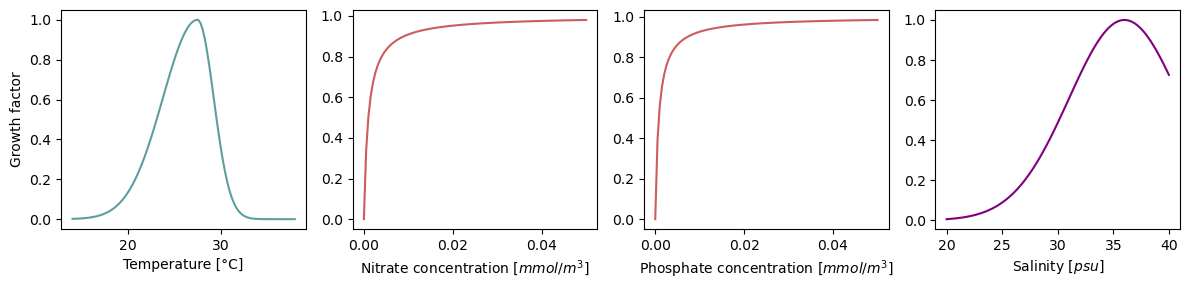

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3))

N = 100
#Temperature growth factor
Trange = np.linspace(14, 38, N)
Tlim = sargassum_kernels.TemperatureGrowthFactor(Trange, fieldset)
ax[0].plot(Trange, Tlim, color='cadetblue')
ax[0].set_xlabel('Temperature [°C]')
ax[0].set_ylabel('Growth factor')

#Nitrogen growth factor
Nrange = np.linspace(0, 0.05, N)
Nlim = sargassum_kernels.NitrogenGrowthFactor(Nrange, fieldset)
ax[1].plot(Nrange, Nlim, color='indianred')
ax[1].set_xlabel('Nitrate concentration [$mmol / m^3$]')

#Phosphorus growth factor
Prange = np.linspace(0, 0.05, N)
Plim = sargassum_kernels.PhosphorusGrowthFactor(Prange, fieldset)
ax[2].plot(Prange, Plim, color='indianred')
ax[2].set_xlabel('Phosphate concentration [$mmol / m^3$]')

#Salinity growth factor
Srange = np.linspace(20, 40, N)
Slim = sargassum_kernels.SalinityGrowthFactor(Srange, fieldset)
ax[3].plot(Srange, Slim, color='purple')
ax[3].set_xlabel('Salinity [$psu$]')

plt.tight_layout()
plt.show()

_Note for advanced users: if you want to change the functional forms of the growth factor curves, instead of only the parameters, you can do that manually in the sargassum_kernels.py file_

## Creating a map of *Sargassum* locations based on satellite detections


To initialize Sargassum particles at locations where actual Sargassum has been detected, we use satellite images of the [Sargassum Watch System (SaWS)](https://optics.marine.usf.edu/projects/saws.html) of the University of South-Florida.  We use the composite FA-UNET-DENSITY-7DAY images, which show the floating algae (FA) density, in terms of percentage of area cover. A value of 0.1 on the color bar indicates 0.1\% surface area coverage by floating algae in that location. The FA density is calculated as a mean of the 7 past days, and is based on the U-Net method described by [Hu et al. (2023)](https://doi.org/10.1016/j.rse.2023.113515). 

The function in the following cell returns a Sargassum release grid based on these SaWS satellite images for a specific date. The `stride` argument controls the spacing (in pixels) between the release locations. Since 1 pixel in the SaWS images is approximately 1 km, using `stride=8` will result in a release map on 8 km resolution, which is the same resolution as the hydrodynamic data in the fieldset. A smaller value for `stride` will result in more particles - and hence a slower simulation.

In [7]:
saws_coords, _ = release_points_from_SaWS_images(
    date=startdate,  # date of the SaWS images to use
    stride=8,  # resolution of the release points [pixels; equivalent to km]
)

We can plot the release locations on a map to check if they are in the right place.

/Users/erik/Codes/Sargassum_growth_model/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


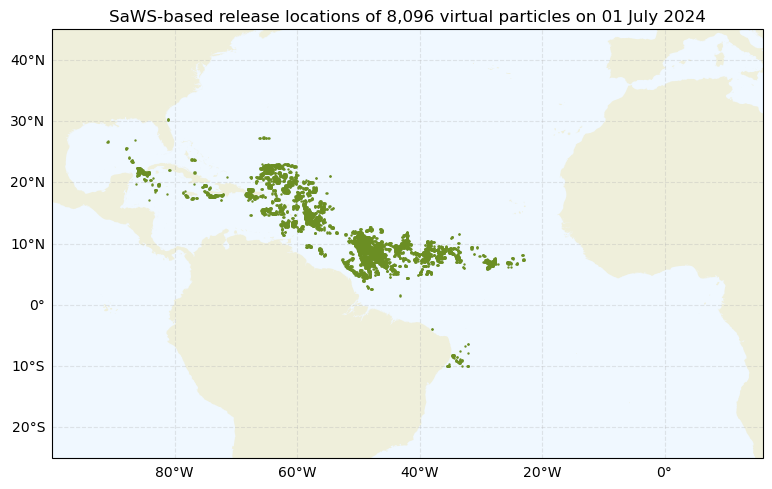

In [8]:
fig = plt.figure(figsize = (10, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_facecolor('aliceblue')
ax.add_feature(cartopy.feature.LAND.with_scale('10m'), zorder=1)
ax.gridlines(draw_labels=['left', 'bottom'], zorder=0, alpha=0.3, linestyle='--')

ax.scatter(saws_coords[:, 0], saws_coords[:, 1], s=0.5, color='olivedrab', zorder=5)
ax.set_extent([-100, 16, -25, 45], crs=ccrs.PlateCarree())
ax.set_title(f'SaWS-based release locations of {len(saws_coords):,} virtual particles on {startdate.strftime("%d %B %Y")}')

plt.tight_layout()
plt.show()


In the manuscript, we set the same initial biomass for each particle, as is also commonly done in other Lagrangian _Sargassum_ simulations ([Debue et al. 2025](https://www.sciencedirect.com/science/article/pii/S0025326X25003984)). However, you can change the initial biomass of the particles by adapting `init_biomass` below.

In [9]:
init_biomass = np.ones(len(saws_coords))

## Setting up the operational kernels to describe *Sargassum* transport and growth

Kernels describe 'operations' that are performed on every particle at every timestep of the simulation. The kernels thereby allow for programming 'behaviour' of the particles. Here, the following kernels were created to describe specific *Sargassum* raft behaviour:
1. `Stranding`: Kernel that accounts for stranding 
2. `AdvectionRK2`: Kernel for advection by ocean currents, using the Runge-Kutta 2nd order method
3. `DepthIntegratedStokesDriftRK2`: Kernel for Stokes drift integrated between upper and lower extent of raft
4. `WindageRK2`: Kernel for inclusion of leeway windage (relative)
5. `SargassumBiologicalGrowthModel`: Kernel for calculation of biomass change, depending on temperature, nitrate availability and salinity. 
6. `DeleteOutOfBounds`: Kernel to delete particles that are out of the (latitudinal) bounds of the fieldset domain.

Users can easily add or remove kernels to adjust the behaviour of the particles. For example, if you want to run a simulation without windage, simply remove the `WindageRK2` kernel from the list.

In [10]:
kernels = [
    sargassum_kernels.Stranding,
    parcels.kernels.AdvectionRK2,
    sargassum_kernels.DepthIntegratedStokesDriftRK2,
    sargassum_kernels.WindageRK2,
    sargassum_kernels.SargassumBiologicalGrowthModel,
    sargassum_kernels.DeleteOutOfBounds,
]

## Executing the simulation

Now, we create an output particle file (`pfile`) and add all the `kernels` that we want to be executed during the simulation, which are formulated in the previous code. At last, we `execute` the simulation based on the satellite-based particle set (`pset`). In the execution step, the total `runtime` of the simulation is determined. It is by default set at 30 days but can be changed as prefered. The timestep of the execution (`dt`) at which the kernels are executed, should not be changed. 

**Note: Running this step can take between 5 to 30 minutes**

In [11]:
#Creating output particle file
pfile = parcels.ParticleFile(
    f"Sargassum_Simulation_{startdate.strftime('%Y-%m-%d')}.parquet",
    outputdt=np.timedelta64(2, 'h'),
)
fieldset.output_file = pfile  # for writing stranded particles

# Create a particleset based on the SaWS release coordinates
pset = parcels.ParticleSet(
    fieldset=fieldset,
    pclass=SargassumParticle,
    x=saws_coords[:, 0],
    y=saws_coords[:, 1],
    z=np.zeros_like(saws_coords[:, 0]),
    t=np.datetime64(startdate),
    biomass=init_biomass,
)

# Do an initial sampling of the Biological Growth Model
# to initialize the particle variables
sargassum_kernels.SargassumBiologicalGrowthModel(pset, fieldset)

pset.execute(
    kernels=kernels,
    endtime=np.datetime64(enddate),
    dt=np.timedelta64(10, 'm'),
    output_file=pfile,
)


INFO: Output files are stored in Sargassum_Simulation_2024-07-01.parquet
Integration time: 2024-07-31T22:00:00 100%|██████████| [07:33<00:00, 5900.08it/s] 


## Exploring and visualizing the output

In this part, we investigate the parquet data file created in the previous step and visualize the output in various ways. 

We start by opening the dataset to see what the variables are

In [12]:
df = parcels.read_particlefile(pfile._path)
df

t,z,y,x,particle_id,temperature,lim_temperature,nitrogen,lim_nitrogen,phosphorus,lim_phosphorus,salinity,lim_salinity,limitation,biomass,stranded
datetime[ns],f32,f32,f32,i64,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,bool
2024-07-01 00:00:00,0.0,21.781816,-61.181801,0,29.382986,0.560526,0.001304,0.565993,0.002509,0.758242,36.511086,0.994789,0.239302,1.0,false
2024-07-01 00:00:00,0.0,21.781816,-60.090881,1,28.825676,0.750568,0.001258,0.557063,0.002418,0.751399,36.752079,0.988751,0.310636,1.0,false
2024-07-01 00:00:00,0.0,21.709087,-63.0,2,29.247795,0.607295,0.001579,0.612277,0.001797,0.691988,36.186111,0.999308,0.257126,1.0,false
2024-07-01 00:00:00,0.0,21.709087,-61.327255,3,29.360216,0.568381,0.001298,0.564865,0.0025,0.75754,36.48035,0.995396,0.242095,1.0,false
2024-07-01 00:00:00,0.0,21.709087,-61.254528,4,29.352512,0.571041,0.001303,0.565864,0.002528,0.759594,36.484627,0.995314,0.244299,1.0,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-08-01 00:00:00,0.0,25.332357,-67.181183,8091,28.445185,0.864281,0.001023,0.505777,0.001784,0.690425,36.597084,0.992895,0.299664,1.492501,false
2024-08-01 00:00:00,0.0,25.798805,-66.689056,8092,28.590467,0.823541,0.001044,0.510826,0.001806,0.693006,36.57439,0.993423,0.289621,1.455752,false
2024-08-01 00:00:00,0.0,25.209303,-67.345772,8093,28.276466,0.906257,0.001022,0.505414,0.001868,0.700117,36.634502,0.99198,0.318106,1.410503,false


In [13]:
domain_extent = (df["x"].min(), df["x"].max(), df["y"].min(), df["y"].max())

The following cell plots the biomass change at the final location of each particle:

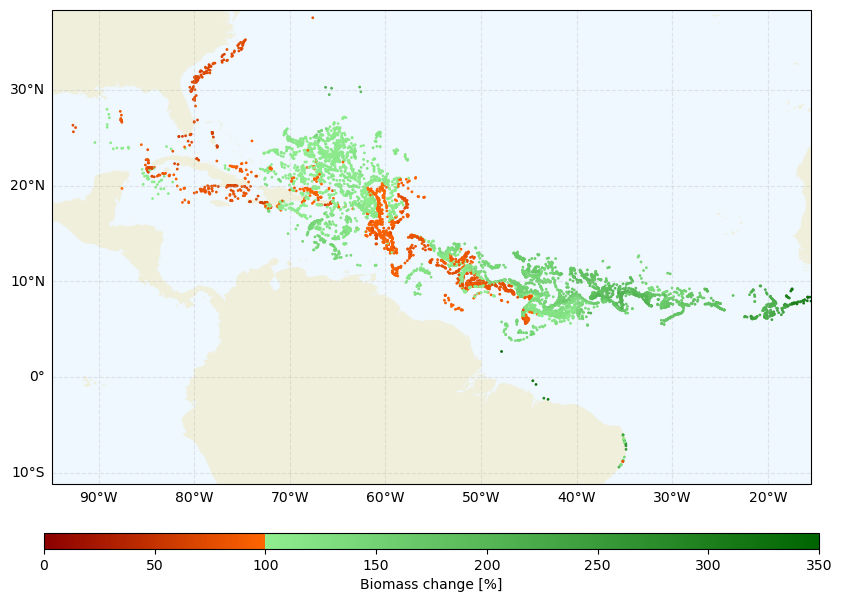

In [14]:
fig = plt.figure(figsize = (10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_facecolor('aliceblue')
ax.gridlines(draw_labels=['left','bottom'], zorder=2, alpha=0.3, linestyle='--')
ax.add_feature(cartopy.feature.LAND.with_scale('10m'))
ax.set_extent(domain_extent, crs=ccrs.PlateCarree())

last_time = df.select(pl.col("t").max()).item()
last_locations = df.filter(pl.col("t") == last_time)
not_stranded = last_locations.filter(pl.col("stranded") == False)

vmax = 350
cscat = ax.scatter(
    not_stranded['x'],
    not_stranded['y'],
    c=not_stranded['biomass'] * 100,
    s=4,
    linewidth=0,
    cmap=biomass_change_cmap(vmax),
    vmin=0,
    vmax=vmax,
    transform=ccrs.PlateCarree(),
    zorder=1
)

cbar = plt.colorbar(cscat, ax=ax, orientation='horizontal', pad=0.08, aspect=50, label='Biomass change [%]')

plt.show()

We can also make an animation of the particles, with the color of the dots indicating the biomass change at that point in time

In [15]:
from matplotlib.animation import FuncAnimation

# for interactive display of animation
plt.rcParams["animation.html"] = "jshtml"

time_step = np.timedelta64(24, "h")  # time step for animation frames

# Build the time axis for the animation.
timerange = np.arange(
    np.nanmin(df["t"]),
    np.nanmax(df["t"]) + time_step,
    time_step,
)

fig = plt.figure(figsize = (8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_facecolor('aliceblue')
ax.gridlines(draw_labels=['left','bottom'], zorder=2, alpha=0.3, linestyle='--')
ax.add_feature(cartopy.feature.LAND.with_scale('10m'))
ax.set_extent(domain_extent, crs=ccrs.PlateCarree())

particles = df.filter(pl.col("t") == pl.lit(timerange[0]))
vmax = 350
cscat = ax.scatter(
    particles['x'],
    particles['y'],
    c=particles['biomass'] * 100,
    s=4,
    linewidth=0,
    cmap=biomass_change_cmap(vmax),
    vmin=0,
    vmax=vmax,
    transform=ccrs.PlateCarree(),
    zorder=1
)

# Set initial title
t_str = pd.to_datetime(timerange[0]).strftime("%Y-%m-%d %H:%M:%S")
title = ax.set_title(f"Particles at t = {t_str}")

cbar = plt.colorbar(cscat, ax=ax, orientation='horizontal', pad=0.08, aspect=50, label='Biomass change [%]')

# loop over for animation
def animate(i):
    t_str = pd.to_datetime(timerange[i]).strftime("%Y-%m-%d %H:%M:%S")
    title.set_text(f"Particles at t = {t_str}")

    # Find particles at current time
    particles = df.filter(pl.col("t") == pl.lit(timerange[i]))

    cscat.set_offsets(np.c_[particles["x"], particles["y"]])
    cscat.set_array(particles["biomass"] * 100)

# Create animation
plt.tight_layout()
anim = FuncAnimation(fig, animate, frames=len(timerange), interval=100)
plt.close(fig)
anim

In the following piece of code, the total growth factor and seperate growth factors of temperature, nitrate availability and salinity are averaged of time for each trajectory. These time-averaged growth factors are then visualized in a boxplot to compare their relative importance in constraining growth.

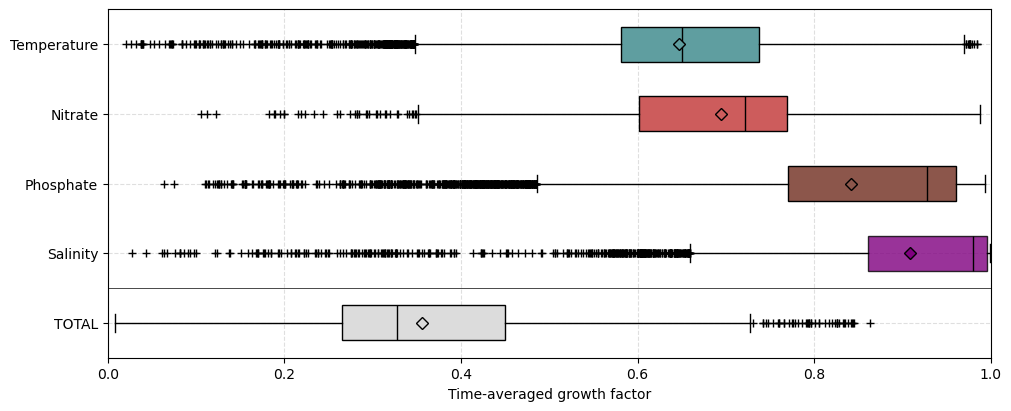

In [ ]:
plt.figure(figsize=(10, 4), constrained_layout=True)

vars = ['limitation', 'lim_salinity', 'lim_phosphorus', 'lim_nitrogen', 'lim_temperature']
limitation_names = ['TOTAL', 'Salinity', 'Phosphate', 'Nitrate', 'Temperature']
colors = ['gainsboro', 'purple', 'tab:brown', 'indianred', 'cadetblue']
alphas = [1, 0.8, 1, 1, 1]

last_time = df.select(pl.col("t").max()).item()
df_reaching_last_time = df.filter(
    (pl.col("t").max().over("particle_id") == last_time) &
    (pl.col("stranded").last().over("particle_id") == False)
)

for i, var in enumerate(vars):
    data = (
        df_reaching_last_time
        .group_by("particle_id")
        .agg(pl.col(var).drop_nans().mean().alias(var))
        .get_column(var)
        .to_numpy()
    )

    plt.boxplot(
        data[~np.isnan(data)],
        positions=[i],
        widths=0.5,
        patch_artist=True,
        orientation='horizontal',
        boxprops={'facecolor': colors[i], 'alpha': alphas[i]},
        medianprops={'color': 'black'},
        showmeans=True,
        meanprops = {'marker': 'D','markeredgecolor': 'black', 'markerfacecolor': colors[i]},
        sym='+',
    )

plt.yticks(range(5) , limitation_names, rotation=0)
plt.xlabel('Time-averaged growth factor')
plt.xlim(0, 1)
plt.hlines(0.5, 0, 1, colors='black', linewidth=0.5)
plt.grid( linestyle='--', alpha=0.4)
plt.show()